# Atividade 2 — Regressão linear multivariada

Adaptação do notebook 2.6: `nn.Linear`, `nn.MSELoss` e `optim.SGD` para oito entradas.

## Dados

O California Housing reúne 20.640 quarteirões. O alvo é o valor mediano dos imóveis em unidades de US$ 100.000. As variáveis são: `MedInc` (renda mediana, em dezenas de milhares de dólares), `HouseAge` (idade mediana das casas), `AveRooms` (média de cômodos por domicílio), `AveBedrms` (média de quartos por domicílio), `Population` (população do quarteirão), `AveOccup` (média de moradores por domicílio), `Latitude` e `Longitude` (localização geográfica).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(1234)
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target
print("Dimensões:", X.shape, y.shape)
display(X.describe())

Dimensões: (20640, 8) (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


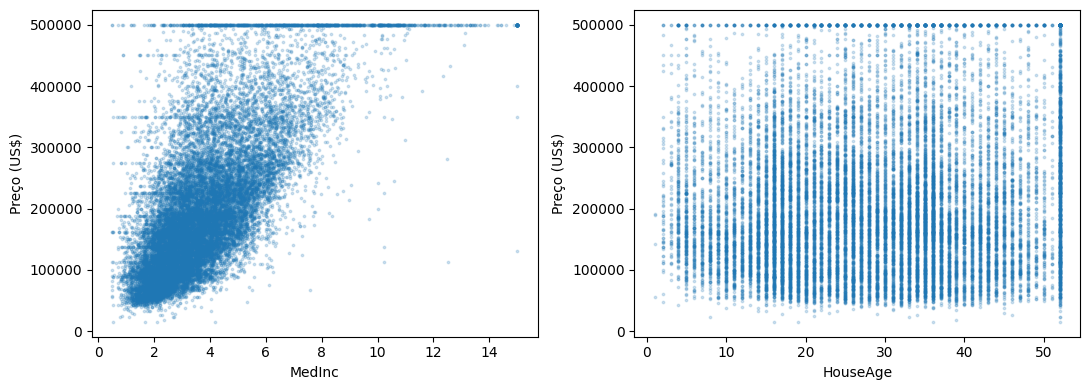

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, coluna in zip(axes, ["MedInc", "HouseAge"]):
    ax.scatter(X[coluna], y * 100000, s=3, alpha=0.2)
    ax.set(xlabel=coluna, ylabel="Preço (US$)")
plt.tight_layout()
plt.show()

## Treino, validação e teste

Divisão 70/15/15. Os dois scalers são ajustados somente no treino.

In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15/0.85, random_state=42)
y_train = y_train.to_numpy().reshape(-1, 1)
y_val = y_val.to_numpy().reshape(-1, 1)
y_test = y_test.to_numpy().reshape(-1, 1)
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)

def tensor_x(data):
    return torch.tensor(x_scaler.transform(data), dtype=torch.float32)
def tensor_y(data):
    return torch.tensor(y_scaler.transform(data), dtype=torch.float32)

x_train, x_val, x_test = map(tensor_x, [X_train, X_val, X_test])
yt_train, yt_val, yt_test = map(tensor_y, [y_train, y_val, y_test])
print("Treino:", len(x_train), "Validação:", len(x_val), "Teste:", len(x_test))

Treino: 14448 Validação: 3096 Teste: 3096


## Modelo e treinamento

In [4]:
model = nn.Linear(8, 1)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)
train_losses, val_losses = [], []
for epoch in range(350):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(x_train), yt_train)
    loss.backward()
    optimizer.step()
    model.eval()
    with torch.no_grad():
        train_losses.append(criterion(model(x_train), yt_train).item())
        val_losses.append(criterion(model(x_val), yt_val).item())
print(f"MSE treino: {train_losses[-1]:.4f} | validação: {val_losses[-1]:.4f}")

MSE treino: 0.3924 | validação: 0.3866


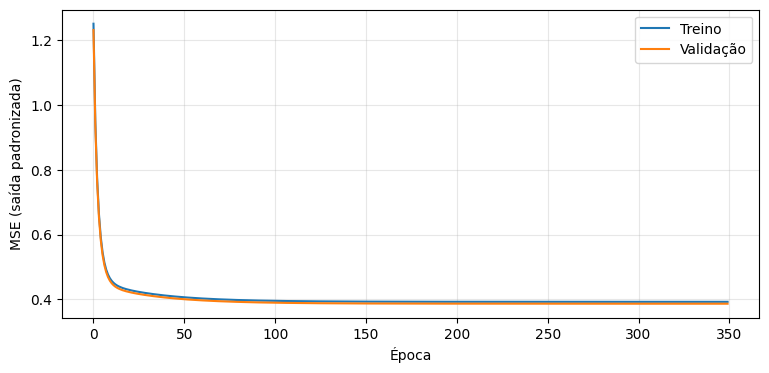

In [5]:
plt.figure(figsize=(9, 4))
plt.plot(train_losses, label="Treino")
plt.plot(val_losses, label="Validação")
plt.xlabel("Época")
plt.ylabel("MSE (saída padronizada)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Teste e baseline

O RMSE é convertido para dólares. O baseline usa sempre a média do preço no treino.

In [6]:
model.eval()
with torch.no_grad():
    pred_padronizado = model(x_test).numpy()
pred_dolares = y_scaler.inverse_transform(pred_padronizado) * 100000
real_dolares = y_test * 100000
rmse_modelo = np.sqrt(np.mean((pred_dolares - real_dolares) ** 2))
media_treino = y_train.mean() * 100000
rmse_baseline = np.sqrt(np.mean((media_treino - real_dolares) ** 2))
print(f"RMSE modelo: US$ {rmse_modelo:,.2f}")
print(f"RMSE baseline: US$ {rmse_baseline:,.2f}")

RMSE modelo: US$ 73,290.42
RMSE baseline: US$ 114,479.20


## Pesos aprendidos

,Peso padronizado
Latitude,-0.767565
Longitude,-0.742067
AveRooms,-0.258884
AveOccup,-0.040046
Population,-0.004076
HouseAge,0.101891
AveBedrms,0.289064
MedInc,0.725956


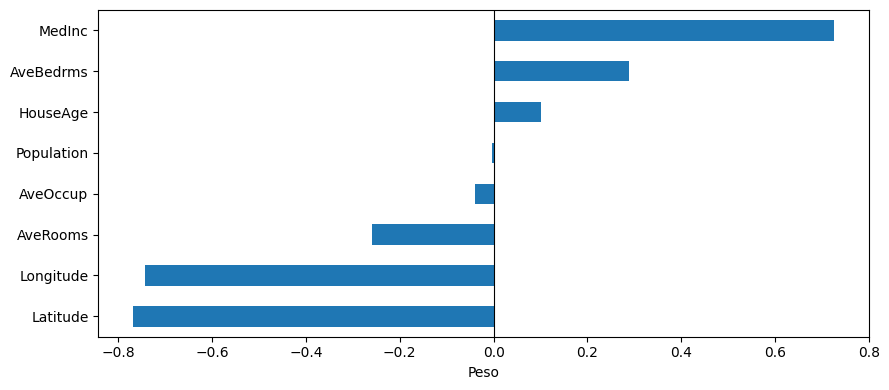

Maior efeito positivo: MedInc
Maior efeito negativo: Latitude


In [7]:
pesos = pd.Series(model.weight.detach().numpy().ravel(), index=X.columns).sort_values()
display(pesos.to_frame("Peso padronizado"))
plt.figure(figsize=(9, 4))
pesos.plot.barh()
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Peso")
plt.tight_layout()
plt.show()
print("Maior efeito positivo:", pesos.idxmax())
print("Maior efeito negativo:", pesos.idxmin())

Como as oito entradas foram padronizadas, cada peso representa a variação prevista na saída padronizada para um aumento de um desvio-padrão naquela entrada, mantendo as demais constantes. Por isso é possível comparar suas magnitudes. Os coeficientes indicam associações condicionais do modelo, não efeitos causais.

## Conclusão

In [8]:
melhora = 100 * (1 - rmse_modelo / rmse_baseline)
print(f"O RMSE ficou {melhora:.1f}% menor que o baseline." if melhora > 0 else "O modelo não superou o baseline.")
print("A regressão linear é um ponto de partida, mas não capta relações não lineares nem interações entre atributos.")
print("Para melhorar, eu testaria Ridge, novas variáveis e modelos não lineares, sempre avaliando no conjunto de validação.")

O RMSE ficou 36.0% menor que o baseline.
A regressão linear é um ponto de partida, mas não capta relações não lineares nem interações entre atributos.
Para melhorar, eu testaria Ridge, novas variáveis e modelos não lineares, sempre avaliando no conjunto de validação.
